# RSO-439: PID history and leaky-integrator verification

This notebook reconstructs the three MTAOS closed-loop tests performed at
Base on 2026-08-27. It progressively demonstrates that:

1. the RSO-439 lifecycle change preserves PID history between images in one
   closed loop, even when `ki=0`;
2. stopping and restarting the closed loop resets that retained history; and
3. `use_leaky_integrator=True` applies the configured finite, exponentially
   weighted error history.


## Experiment matrix

| Run | Visits | Configuration | Purpose |
| --- | --- | --- | --- |
| 1 | `2026082700001-0003` | config `develop`, `ki=0`, leaky keys omitted | Prove history is retained although the integral does not affect corrections. |
| 2 | `2026082700005-0009` | `54af571`, `ki=0.5`, `use_leaky_integrator=False` | Prove the history reset between visits `0007` and `0008`. |
| 3 | `2026082700010-0013` | `5cd4b37`, `ki=0.5`, `use_leaky_integrator=True`, `n_iterms=10`, `i_factor=0.5` | Prove finite exponentially weighted accumulation. |

Run 2 reports visits `0005-0009`. Visit `0004` is retained only as hidden
controller-history context because the BTS playlist, but not the MTAOS closed
loop, was reset before `0005`. The loop restarts before visits `0008-0009`.
Run 3 begins after another reset and replays four comparable image inputs.

The BTS supplies a predetermined image playlist. Corrections issued by MTAOS
do not modify the image or Zernike coefficients presented at the next playlist
step. This isolates controller-history behavior from physical optical feedback.
Because the same images were replayed through the same WEP processing, their
paired `lsst.sal.MTAOS.logevent_wavefrontError` values are expected to be
exactly equal; the identity check below tests that expectation.

The EFD windows below are UTC and include padding around the relevant events.
MTAOS logs display TAI, which was 37 seconds ahead of UTC during these tests.

## Controller equations

Let $e_k$ be the PID error for one active DOF at correction step $k$.

For the ordinary cumulative integrator used in runs 1 and 2, the current
implementation adds the new error to the previously clipped integral:

$$J_k = I_{k-1} + e_k$$
$$I_k = \mathrm{clip}(J_k, -I_{\max}, I_{\max})$$

For the leaky integrator in run 3, the newest error has weight 1 and each
older retained error is reduced by `i_factor = f`:

$$J_k = \sum_{j=0}^{\min(k, n-1)} f^j e_{k-j}$$
$$I_k = \mathrm{clip}(J_k, -I_{\max}, I_{\max})$$

With `f=0.5`, the first three raw integrals are:

$$J_1=e_1, \quad J_2=0.5e_1+e_2, \quad
J_3=0.25e_1+0.5e_2+e_3.$$

The final controller output is:

$$u_k = K_p e_k + K_i I_k + K_d D_k.$$

All three tests used `Kp=0.3` and `Kd=0`. Runs 2 and 3 used `Ki=0.5`.
A history reset is visible when the first raw integral of a new lifecycle is
equal to its current error.

In [108]:
from collections import deque
import re
import warnings

from astropy.time import Time
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lsst_efd_client import EfdClient

%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (11, 5),
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Configuration

`EFD_NAME="base"` resolves to `base_efd`. The three windows and expected
visit IDs are already filled from the test logs. Adjust only if the Base EFD
timestamps reveal an adjacent event just outside a boundary.

In [109]:
EFD_ALIASES = {
    "base": "base_efd",
    "summit": "summit_efd",
    "usdf": "usdf_efd",
}
EFD_NAME = "base"

RUNS = {
    "run_1_ki0": {
        "label": "Run 1: cumulative, Ki=0",
        "start": "2026-08-27T21:35:00Z",
        "end": "2026-08-27T21:56:00Z",
        "visits": [2026082700001, 2026082700002, 2026082700003],
        "lifecycles": [[2026082700001, 2026082700002, 2026082700003]],
        "kp": 0.3,
        "ki": 0.0,
        "kd": 0.0,
        "use_leaky_integrator": False,
        "n_iterms": 1,
        "i_factor": 1.0,
        "config": "ts_config_mttcs develop; leaky keys omitted",
    },
    "run_2_cumulative_ki05": {
        "label": "Run 2: cumulative, Ki=0.5",
        "start": "2026-08-27T22:00:00Z",
        "end": "2026-08-27T22:33:30Z",
        "visits": [
            2026082700005,
            2026082700006,
            2026082700007,
            2026082700008,
            2026082700009,
        ],
        "lifecycles": [
            [2026082700004, 2026082700005, 2026082700006, 2026082700007],
            [2026082700008, 2026082700009],
        ],
        "kp": 0.3,
        "ki": 0.5,
        "kd": 0.0,
        "use_leaky_integrator": False,
        "n_iterms": 10,
        "i_factor": 0.5,
        "config": "ts_config_mttcs 54af571",
    },
    "run_3_leaky_ki05": {
        "label": "Run 3: leaky, Ki=0.5, f=0.5",
        "start": "2026-08-27T22:44:00Z",
        "end": "2026-08-27T23:02:00Z",
        "visits": [2026082700010, 2026082700011, 2026082700012, 2026082700013],
        "lifecycles": [
            [2026082700010, 2026082700011, 2026082700012, 2026082700013]
        ],
        "kp": 0.3,
        "ki": 0.5,
        "kd": 0.0,
        "use_leaky_integrator": True,
        "n_iterms": 10,
        "i_factor": 0.5,
        "config": "ts_config_mttcs 5cd4b37",
    },
}

ACTIVE_DOFS = np.array(
    [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 30, 31, 32, 33, 34],
    dtype=int,
)
MAX_INTEGRAL_50 = np.array(
    [
        500, 100, 100, 0.01, 0.01,
        500, 100, 100, 0.01, 0.01,
        0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5,
        0, 0, 0, 0, 0,
        0, 0, 0, 0, 0,
        0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5,
        0, 0, 0, 0, 0,
        0, 0, 0, 0, 0,
    ],
    dtype=float,
)
MAX_INTEGRAL = MAX_INTEGRAL_50[ACTIVE_DOFS]

DOF_LABELS = {
    0: "M2 dZ piston [um]",
    1: "M2 dX [um]",
    2: "M2 dY [um]",
    3: "M2 rX [arcsec]",
    4: "M2 rY [arcsec]",
    5: "Camera dZ [um]",
    10: "M1M3 bending mode 1 [um]",
    30: "M2 bending mode 1 [um]",
}
DISPLAY_DOFS = [0, 3, 10, 30]
WFE_ARRAY_COUNT = 100
WFE_NOLL_INDICES = [*range(4, 20), *range(22, 27)]
WFE_VISIT_PAIRS = [
    (2026082700001, 2026082700010),
    (2026082700002, 2026082700011),
    (2026082700003, 2026082700012),
]

In [110]:
dof_map = []
for vector_index, global_dof in enumerate(ACTIVE_DOFS):
    if global_dof < 5:
        component = ["M2 dZ", "M2 dX", "M2 dY", "M2 rX", "M2 rY"][global_dof]
    elif global_dof < 10:
        component = ["Camera dZ", "Camera dX", "Camera dY", "Camera rX", "Camera rY"][global_dof - 5]
    elif global_dof < 30:
        component = f"M1M3 bending mode {global_dof - 9}"
    else:
        component = f"M2 bending mode {global_dof - 29}"
    dof_map.append(
        {
            "PID vector index": vector_index,
            "global DOF": global_dof,
            "component": component,
            "max integral": MAX_INTEGRAL_50[global_dof],
        }
    )

display(pd.DataFrame(dof_map))

,PID vector index,global DOF,component,max integral
0,0,0,M2 dZ,500.00
1,1,1,M2 dX,100.00
2,2,2,M2 dY,100.00
3,3,3,M2 rX,0.01
4,4,4,M2 rY,0.01
5,5,5,Camera dZ,500.00
6,6,6,Camera dX,100.00
7,7,7,Camera dY,100.00
8,8,8,Camera rX,0.01
9,9,9,Camera rY,0.01


## EFD topics

The authoritative PID arrays for these tests are embedded in
`lsst.sal.MTAOS.logevent_logMessage.message`:

- error before gains;
- integral before clipping;
- integral after clipping; and
- correction after `Kp/Ki/Kd`.

All controller values used in the three PID analyses come from this message
topic. `lsst.sal.MTAOS.logevent_degreeOfFreedom.visitId` is queried only to
associate each nearby PID report with its visit. Closed-loop commands establish
the lifecycle boundary, and `logevent_wavefrontError` is reserved for the
independent Noll-index analysis at the end.

In [111]:
def vector_fields(prefix, indices):
    return [f"{prefix}{index}" for index in indices]


TOPIC_FIELDS = {
    "pid_log": (
        "lsst.sal.MTAOS.logevent_logMessage",
        [
            "filePath",
            "functionName",
            "name",
            "message",
            "traceback",
            "lineNumber",
            "level",
        ],
    ),
    "degree_of_freedom": (
        "lsst.sal.MTAOS.logevent_degreeOfFreedom",
        ["visitId"],
    ),
    "start_closed_loop_command": (
        "lsst.sal.MTAOS.command_startClosedLoop",
        ["config", "private_sndStamp", "private_identity"],
    ),
    "stop_closed_loop_command": (
        "lsst.sal.MTAOS.command_stopClosedLoop",
        ["private_sndStamp", "private_identity"],
    ),
    "wavefront_error": (
        "lsst.sal.MTAOS.logevent_wavefrontError",
        ["sensorId", "visitId", "extraId"]
        + vector_fields("nollZernikeIndices", range(WFE_ARRAY_COUNT))
        + vector_fields("nollZernikeValues", range(WFE_ARRAY_COUNT)),
    ),
}


def resolve_efd_instance(efd_name):
    return EFD_ALIASES.get(efd_name, efd_name)


def available_field_names(fields):
    if isinstance(fields, dict):
        return set(fields)
    return {
        field.get("name") if isinstance(field, dict) else field
        for field in fields
    }


async def query_run(client, config):
    start = Time(config["start"], scale="utc")
    end = Time(config["end"], scale="utc")
    output = {}

    # Query sequentially and request only fields used in this notebook.
    for label, (topic, requested_fields) in TOPIC_FIELDS.items():
        try:
            if label == "pid_log":
                # message is the only field required to reconstruct the PID report.
                # Query it directly because get_fields() has returned different
                # metadata shapes across efd-client versions.
                fields = ["message"]
            else:
                available = available_field_names(await client.get_fields(topic))
                fields = [
                    field for field in requested_fields if field in available
                ]
            if not fields:
                warnings.warn(f"No requested fields are available for {topic}")
                output[label] = pd.DataFrame()
                continue
            output[label] = await client.select_time_series(
                topic,
                fields,
                start,
                end,
            )
        except Exception as exc:
            warnings.warn(f"Could not query {topic}: {exc}")
            output[label] = pd.DataFrame()
    return output


async def query_all_runs(runs=RUNS, efd_name=EFD_NAME):
    client = EfdClient(resolve_efd_instance(efd_name))
    output = {}
    for run_name, config in runs.items():
        output[run_name] = await query_run(client, config)
    return output

In [112]:
# Execute this cell in an authenticated notebook environment.
efd_data = await query_all_runs()

query_counts = pd.DataFrame(
    {
        run_name: {
            topic_name: len(frame)
            for topic_name, frame in run_data.items()
        }
        for run_name, run_data in efd_data.items()
    }
).fillna(0).astype(int)
display(query_counts)

pid_query_diagnostics = []
pid_marker_pattern = (
    r"Error before any gains|Integral component before clipping|"
    r"Corrections after Kp/Ki/Kd gains"
)
for run_name, run_data in efd_data.items():
    log_frame = run_data["pid_log"]
    message_columns = [
        column
        for column in log_frame.columns
        if str(column) == "message" or str(column).endswith(".message")
    ]
    message_column = message_columns[0] if message_columns else None
    marker_rows = 0
    if message_column is not None:
        marker_rows = int(
            log_frame[message_column]
            .astype(str)
            .str.contains(pid_marker_pattern, regex=True, na=False)
            .sum()
        )
    pid_query_diagnostics.append(
        {
            "run": run_name,
            "logMessage rows": len(log_frame),
            "message column": message_column,
            "rows with PID markers": marker_rows,
        }
    )

display(pd.DataFrame(pid_query_diagnostics).set_index("run"))

,run_1_ki0,run_2_cumulative_ki05,run_3_leaky_ki05
pid_log,127,250,166
degree_of_freedom,3,6,4
start_closed_loop_command,0,2,1
stop_closed_loop_command,1,2,0
wavefront_error,12,24,16


,logMessage rows,message column,rows with PID markers
run,,,
run_1_ki0,127,message,3
run_2_cumulative_ki05,250,message,6
run_3_leaky_ki05,166,message,4


## Parse and validate the PID logs

A PID report contains four vectors. Depending on the deployed logging stack,
the report may be stored in one multiline EFD row or split across consecutive
rows. The parser accepts both representations, while remaining strict about
vector lengths and the expected number of visits. This prevents a partial EFD
window from silently producing a persuasive but incorrect plot.

In [113]:
PID_PATTERNS = {
    "error": re.compile(
        r"Error before any gains in whichever basis PID is\s*(\[[\s\S]*?\])",
    ),
    "integral_raw": re.compile(
        r"Integral component before clipping is\s*(\[[\s\S]*?\])",
    ),
    "integral_clipped": re.compile(
        r"Integral component is\s*(\[[\s\S]*?\])",
    ),
    "correction": re.compile(
        r"Corrections after Kp/Ki/Kd gains is\s*(\[[\s\S]*?\])",
    ),
}


def parse_vector(text):
    normalized = text.strip("[]").replace("\n", " ").replace(",", " ")
    return np.fromstring(normalized, sep=" ")


def find_message_column(log_frame):
    for column in log_frame.columns:
        if str(column) == "message" or str(column).endswith(".message"):
            return column
    return None


def parse_pid_logs(log_frame):
    if log_frame.empty:
        return pd.DataFrame()

    message_column = find_message_column(log_frame)
    if message_column is None:
        warnings.warn("The PID log query did not return a message column")
        return pd.DataFrame()

    records = []
    malformed = []
    pending = None
    for timestamp, row in log_frame.sort_index().iterrows():
        message = str(row[message_column])
        matches = {
            name: pattern.search(message)
            for name, pattern in PID_PATTERNS.items()
        }
        if not any(matches.values()):
            continue

        if matches["error"] is not None:
            if pending is not None:
                malformed.append(pending["time"])
            pending = {"time": timestamp}
        elif pending is None:
            malformed.append(timestamp)
            continue

        for name, match in matches.items():
            if match is None:
                continue
            value = parse_vector(match.group(1))
            if len(value) != len(ACTIVE_DOFS):
                raise ValueError(
                    f"PID vector {name} at {timestamp} has {len(value)} "
                    f"elements; expected {len(ACTIVE_DOFS)}."
                )
            pending[name] = value

        if all(name in pending for name in PID_PATTERNS):
            records.append(pending)
            pending = None

    if pending is not None:
        malformed.append(pending["time"])
    if malformed:
        warnings.warn(f"Ignored incomplete PID reports starting at: {malformed}")
    if not records:
        return pd.DataFrame()
    return pd.DataFrame(records).set_index("time").sort_index()


def match_pid_visits(pid, degree_frame, tolerance="1s"):
    visit_columns = [
        column
        for column in degree_frame.columns
        if str(column) == "visitId" or str(column).endswith(".visitId")
    ]
    if degree_frame.empty or not visit_columns:
        raise ValueError(
            "Cannot associate PID reports with visits because the "
            "degreeOfFreedom query returned no visitId values."
        )

    visit_column = visit_columns[0]
    visit_events = (
        degree_frame[[visit_column]]
        .dropna()
        .rename(columns={visit_column: "visitId"})
        .rename_axis("degree_time")
        .reset_index()
        .sort_values("degree_time")
    )
    pid_events = (
        pid.rename_axis("pid_time")
        .reset_index()
        .sort_values("pid_time")
    )
    matched = pd.merge_asof(
        pid_events,
        visit_events,
        left_on="pid_time",
        right_on="degree_time",
        direction="nearest",
        tolerance=pd.Timedelta(tolerance),
    )
    if matched["visitId"].isna().any():
        unmatched = matched.loc[matched["visitId"].isna(), "pid_time"].tolist()
        raise ValueError(
            f"Could not match PID reports at {unmatched} to degreeOfFreedom "
            f"events within {tolerance}."
        )

    matched["visitId"] = matched["visitId"].astype(np.int64)
    if matched["visitId"].duplicated().any():
        duplicates = matched.loc[matched["visitId"].duplicated(), "visitId"].tolist()
        raise ValueError(f"Multiple PID reports matched visits {duplicates}")
    return (
        matched.drop(columns="degree_time")
        .set_index("pid_time")
        .rename_axis("time")
        .sort_index()
    )


def gain_vector(value):
    array = np.asarray(value, dtype=float)
    if array.ndim == 0:
        return np.full(len(ACTIVE_DOFS), float(array))
    if len(array) == 50:
        return array[ACTIVE_DOFS]
    if len(array) == len(ACTIVE_DOFS):
        return array
    raise ValueError(f"Cannot map gain with shape {array.shape} to active DOFs")


def analyze_pid_run(run_name, run_data, config):
    log_frame = run_data["pid_log"]
    pid = parse_pid_logs(log_frame).copy()
    expected_visits = config["visits"]
    history_visits = [
        visit for lifecycle in config["lifecycles"] for visit in lifecycle
    ]
    if pid.empty:
        raise ValueError(
            f"{run_name}: found no complete PID records for visits "
            f"{expected_visits}. "
            f"The EFD query returned {len(log_frame)} logMessage rows. "
            "Inspect pid_query_diagnostics to determine whether the time "
            "window is empty or the returned messages lack PID markers."
        )

    pid = match_pid_visits(pid, run_data["degree_of_freedom"])
    observed_visits = pid["visitId"].tolist()
    missing_visits = [
        visit for visit in history_visits if visit not in observed_visits
    ]
    if missing_visits:
        raise ValueError(
            f"{run_name}: no PID report was matched to required history "
            f"visits {missing_visits}. "
            f"Matched visits were {observed_visits}."
        )
    pid = pid.loc[pid["visitId"].isin(history_visits)].copy()
    if pid["visitId"].tolist() != history_visits:
        raise ValueError(
            f"{run_name}: PID reports were not ordered as expected. "
            f"Expected {history_visits}, found {pid['visitId'].tolist()}."
        )
    pid["visit"] = [
        f"{visit % 100000:05d}" for visit in pid["visitId"]
    ]

    lifecycle_by_visit = {}
    for lifecycle_number, visits in enumerate(config["lifecycles"], start=1):
        for history_step, visit in enumerate(visits, start=1):
            lifecycle_by_visit[visit] = (lifecycle_number, history_step)

    kp = gain_vector(config["kp"])
    ki = gain_vector(config["ki"])
    kd = gain_vector(config["kd"])
    if np.any(kd != 0):
        raise NotImplementedError("This notebook expects Kd=0 for all three tests")

    expected_integrals = []
    hypothetical_cumulative_raw = []
    hypothetical_cumulative_clipped = []
    hypothetical_cumulative_correction = []
    lifecycle_numbers = []
    history_steps = []

    previous_observed_clipped = None
    previous_hypothetical_clipped = None
    error_history = deque(maxlen=config["n_iterms"])
    current_lifecycle = None

    for _, row in pid.iterrows():
        lifecycle_number, history_step = lifecycle_by_visit[row["visitId"]]
        if lifecycle_number != current_lifecycle:
            current_lifecycle = lifecycle_number
            previous_observed_clipped = np.zeros(len(ACTIVE_DOFS))
            previous_hypothetical_clipped = np.zeros(len(ACTIVE_DOFS))
            error_history.clear()

        error = row["error"]
        error_history.append(error)

        if config["use_leaky_integrator"]:
            ages = np.arange(len(error_history) - 1, -1, -1)
            weights = config["i_factor"] ** ages
            expected_integral = np.sum(
                np.asarray(error_history) * weights[:, None],
                axis=0,
            )
        else:
            expected_integral = previous_observed_clipped + error

        cumulative_raw = previous_hypothetical_clipped + error
        cumulative_clipped = np.clip(
            cumulative_raw,
            -MAX_INTEGRAL,
            MAX_INTEGRAL,
        )

        expected_integrals.append(expected_integral)
        hypothetical_cumulative_raw.append(cumulative_raw)
        hypothetical_cumulative_clipped.append(cumulative_clipped)
        hypothetical_cumulative_correction.append(
            kp * error + ki * cumulative_clipped
        )
        lifecycle_numbers.append(lifecycle_number)
        history_steps.append(history_step)

        previous_observed_clipped = row["integral_clipped"]
        previous_hypothetical_clipped = cumulative_clipped

    pid["lifecycle"] = lifecycle_numbers
    pid["history_step"] = history_steps
    pid["integral_expected"] = expected_integrals
    pid["hypothetical_cumulative_raw"] = hypothetical_cumulative_raw
    pid["hypothetical_cumulative_clipped"] = hypothetical_cumulative_clipped
    pid["hypothetical_cumulative_correction"] = hypothetical_cumulative_correction
    pid["correction_expected"] = [
        kp * error + ki * integral
        for error, integral in zip(pid["error"], pid["integral_clipped"])
    ]
    pid["integral_residual_max"] = [
        np.max(np.abs(observed - expected))
        for observed, expected in zip(pid["integral_raw"], pid["integral_expected"])
    ]
    pid["correction_residual_max"] = [
        np.max(np.abs(observed - expected))
        for observed, expected in zip(pid["correction"], pid["correction_expected"])
    ]
    pid["integral_equals_error"] = [
        np.allclose(integral, error, atol=1e-6, rtol=1e-8)
        for integral, error in zip(pid["integral_raw"], pid["error"])
    ]
    pid["clipped_dof_count"] = [
        int(np.count_nonzero(~np.isclose(raw, clipped)))
        for raw, clipped in zip(pid["integral_raw"], pid["integral_clipped"])
    ]
    return pid.loc[pid["visitId"].isin(expected_visits)].copy()


pid_runs = {
    run_name: analyze_pid_run(run_name, efd_data[run_name], config)
    for run_name, config in RUNS.items()
}

## Telemetry coverage

This compact audit confirms that each EFD window contains the expected PID
reports and supporting lifecycle or wavefront-error records. The controller
analysis below does not use structured DOF arrays; its error, integral, and
correction values are parsed from `logevent_logMessage.message`.

In [114]:
coverage_rows = []
for run_name, run_data in efd_data.items():
    coverage_rows.append(
        {
            "run": run_name,
            "PID records": len(pid_runs[run_name]),
            "startClosedLoop commands": len(run_data["start_closed_loop_command"]),
            "stopClosedLoop commands": len(run_data["stop_closed_loop_command"]),
            "WFE sensor events": len(run_data["wavefront_error"]),
        }
    )

display(pd.DataFrame(coverage_rows).set_index("run"))

,PID records,startClosedLoop commands,stopClosedLoop commands,WFE sensor events
run,,,,
run_1_ki0,3,0,1,12
run_2_cumulative_ki05,5,2,2,24
run_3_leaky_ki05,4,1,0,16


In [115]:
def pid_index(global_dof):
    matches = np.flatnonzero(ACTIVE_DOFS == global_dof)
    if len(matches) != 1:
        raise ValueError(f"Global DOF {global_dof} is not active")
    return int(matches[0])


def vector_component(series, global_dof):
    index = pid_index(global_dof)
    return np.array([value[index] for value in series], dtype=float)


def pid_configuration_label(config):
    leaky_setting = str(config["use_leaky_integrator"])
    if "leaky keys omitted" in config["config"]:
        leaky_setting += " (configuration keys omitted)"
    label = (
        "MTAOS PID configuration: "
        f"Kp={config['kp']:g}, Ki={config['ki']:g}, "
        f"Kd={config['kd']:g}, use_leaky_integrator={leaky_setting}"
    )
    if config["use_leaky_integrator"]:
        label += (
            f", n_iterms={config['n_iterms']}, "
            f"i_factor={config['i_factor']:g}"
        )
    return label


def pid_history_summary(pid):
    rows = []
    for _, pid_row in pid.iterrows():
        equal_components = np.isclose(
            pid_row["integral_raw"],
            pid_row["error"],
            atol=1e-6,
            rtol=1e-8,
        )
        rows.append(
            {
                "visitId": int(pid_row["visitId"]),
                "lifecycle": int(pid_row["lifecycle"]),
                "historyStep": int(pid_row["history_step"]),
                "activeDofsIntegralEqualsError": int(equal_components.sum()),
                "activeDofsWithAccumulatedHistory": int((~equal_components).sum()),
                "allActiveDofsIntegralEqualsError": bool(equal_components.all()),
                "maxAbsRecurrenceResidual": float(
                    pid_row["integral_residual_max"]
                ),
            }
        )
    return pd.DataFrame(rows)


def plot_logged_error_and_integral(
    pid,
    title,
    config,
    global_dofs=DISPLAY_DOFS,
    reset_visit_id=None,
):
    fig, axes = plt.subplots(
        len(global_dofs),
        1,
        figsize=(11, 4.2 * len(global_dofs)),
        squeeze=False,
    )
    x = np.arange(len(pid))
    labels = pid["visitId"].astype(str).tolist()

    for axis, global_dof in zip(axes[:, 0], global_dofs):
        axis.plot(
            x,
            vector_component(pid["error"], global_dof),
            "o-",
            linewidth=2,
            label="current error (PID log)",
        )
        axis.plot(
            x,
            vector_component(pid["integral_raw"], global_dof),
            "s--",
            linewidth=2,
            label="integral before clipping (PID log)",
        )
        axis.plot(
            x,
            vector_component(pid["integral_expected"], global_dof),
            "k--",
            linewidth=1.2,
            label="expected configured recurrence",
        )
        if reset_visit_id is not None:
            reset_matches = np.flatnonzero(
                pid["visitId"].to_numpy() == reset_visit_id
            )
            if len(reset_matches) != 1:
                raise ValueError(f"Expected one reset visit {reset_visit_id}")
            reset_position = int(reset_matches[0])
            axis.axvline(
                reset_position - 0.5,
                color="black",
                linestyle=":",
            )
            axis.axvspan(
                reset_position - 0.12,
                reset_position + 0.12,
                color="tab:green",
                alpha=0.12,
            )
        axis.set_title(DOF_LABELS.get(global_dof, f"Global DOF {global_dof}"))
        axis.set_xticks(x, labels)
        axis.tick_params(axis="x", labelrotation=25)
        axis.set_xlabel(
            "visitId (lsst.sal.MTAOS.logevent_degreeOfFreedom)"
        )
        axis.set_ylabel("logged PID value")
        axis.legend(ncol=3)

    fig.suptitle(title, fontsize=14, y=0.995)
    fig.text(
        0.5,
        0.975,
        pid_configuration_label(config),
        ha="center",
        va="top",
        fontsize=10,
        bbox={"boxstyle": "round,pad=0.3", "facecolor": "0.95"},
    )
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig

## Evidence 1: ordinary accumulation within one closed loop

The first PID sample after the loop starts should have `integral == error`.
Later samples should satisfy the cumulative recurrence and separate from the
current error alone. Every plotted controller value is parsed from the Run 1
MTAOS PID messages. Since `Ki=0`, the retained history is observable without
affecting the correction, isolating the RSO-439 history fix from feedback.

,visitId,lifecycle,historyStep,activeDofsIntegralEqualsError,activeDofsWithAccumulatedHistory,allActiveDofsIntegralEqualsError,maxAbsRecurrenceResidual
0,2026082700001,1,1,22,0,True,0.000000e+00
1,2026082700002,1,2,0,22,False,5.000000e-07
2,2026082700003,1,3,0,22,False,4.000000e-06


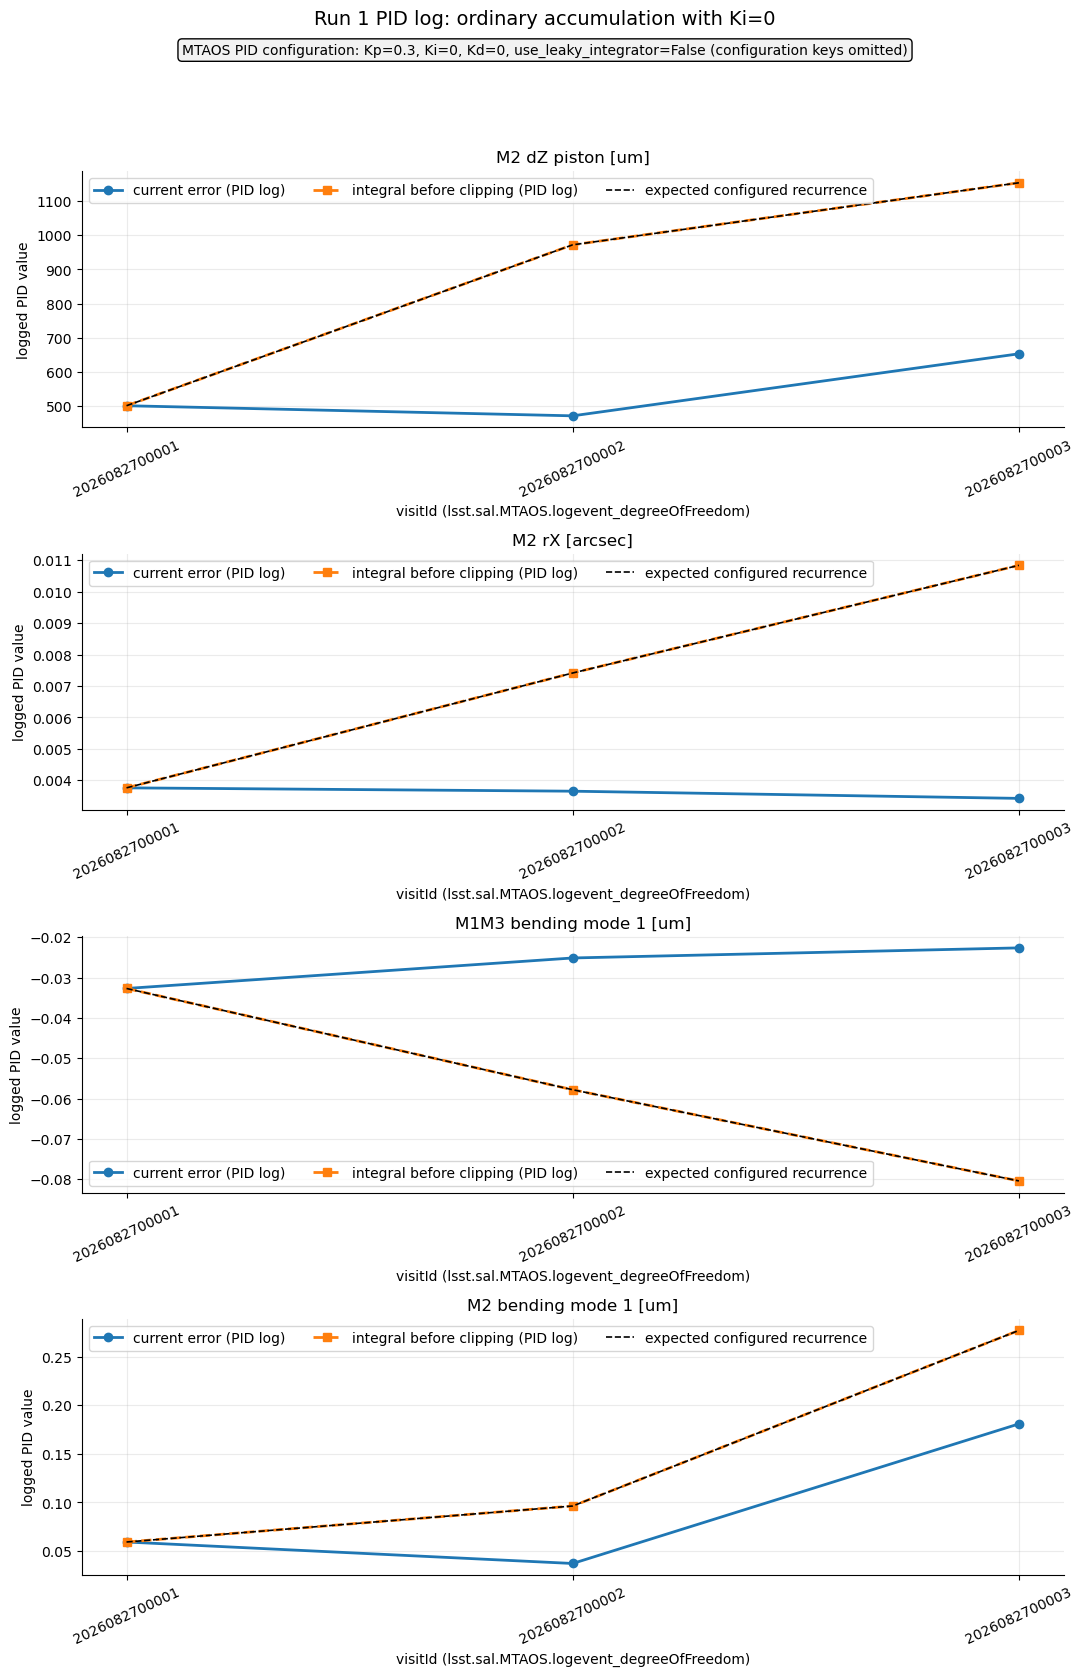

In [116]:
run_1 = pid_runs["run_1_ki0"]
display(pid_history_summary(run_1))
plot_logged_error_and_integral(
    run_1,
    "Run 1 PID log: ordinary accumulation with Ki=0",
    RUNS["run_1_ki0"],
);

## Evidence 2: history reset at the closed-loop boundary

Visit `0004` is excluded from the displayed sequence after the BTS playlist
reset, but it remains in the PID-history calculation because MTAOS stayed in
the same closed loop. MTAOS was stopped and started between visits `0007` and
`0008`. The first PID report after that boundary must return to
`integral == error` for all 22 active DOFs; visit `0009` should then accumulate
again. The table and plot use the Run 2 PID messages for this check.

,visitId,lifecycle,historyStep,activeDofsIntegralEqualsError,activeDofsWithAccumulatedHistory,allActiveDofsIntegralEqualsError,maxAbsRecurrenceResidual
0,2026082700005,1,2,0,22,False,2.000000e-06
1,2026082700006,1,3,0,22,False,5.000000e-06
2,2026082700007,1,4,0,22,False,3.000000e-06
3,2026082700008,2,1,22,0,True,0.000000e+00
4,2026082700009,2,2,0,22,False,1.000000e-09


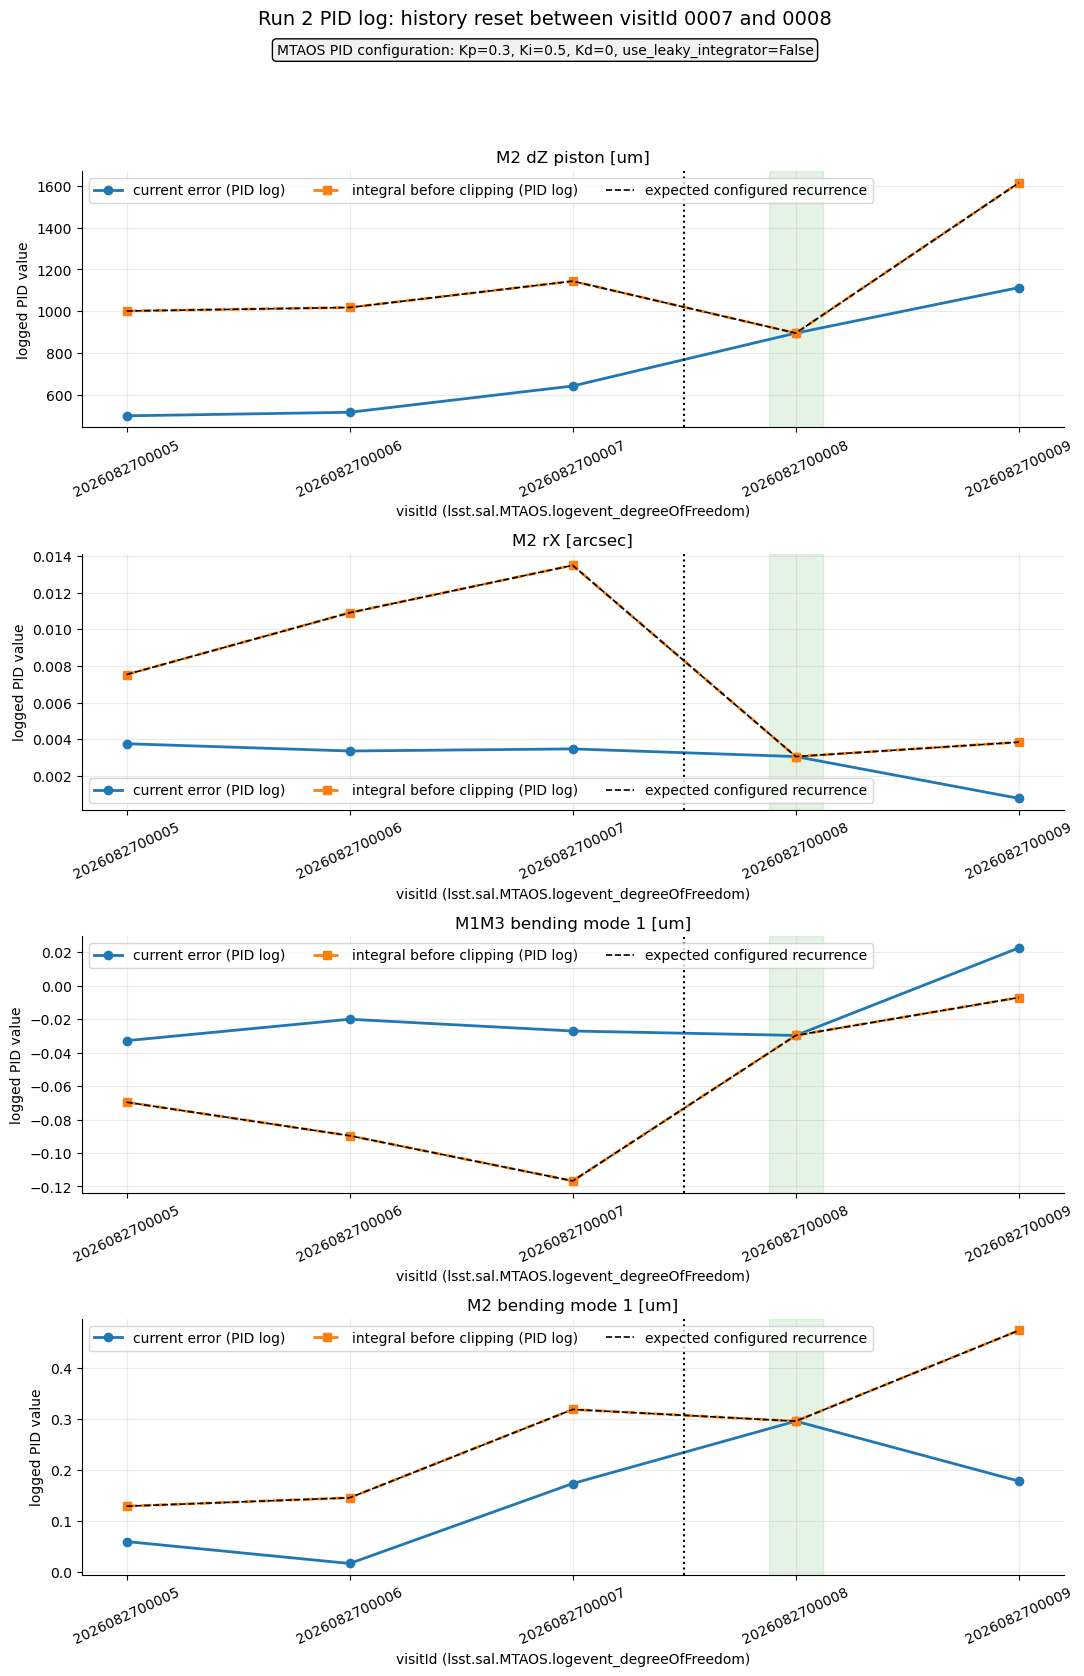

In [117]:
run_2 = pid_runs["run_2_cumulative_ki05"]
reset_summary = pid_history_summary(run_2)
display(reset_summary)
plot_logged_error_and_integral(
    run_2,
    "Run 2 PID log: history reset between visitId 0007 and 0008",
    RUNS["run_2_cumulative_ki05"],
    reset_visit_id=2026082700008,
);

## Evidence 3: leaky accumulation from one PID sequence

Run 3 provides one uninterrupted sequence with `Ki=0.5`,
`use_leaky_integrator=True`, and `i_factor=0.5`. The comparison below uses
only its MTAOS PID messages, avoiding changes in input error between runs.

In [118]:
run_3 = pid_runs["run_3_leaky_ki05"]

### Same-error leaky versus cumulative counterfactual

This comparison uses only the Run 3 MTAOS PID log. The observed error vector
from every `visitId` is passed through two histories: the configured leaky
integrator and a counterfactual pure cumulative integrator. Both use the same
`Kp`, `Ki`, clipping limits, and current errors, so any difference is caused
only by the integral-history rule.

The controller vectors come from
`lsst.sal.MTAOS.logevent_logMessage.message`, not from the structured
`degreeOfFreedom.integralError` fields. In particular, the notebook parses the
current error from `Error before any gains...`, the clipped leaky integral from
`Integral component is...`, and the applied PID result from
`Corrections after Kp/Ki/Kd gains...`. The current error is used by both
calculations but is not itself plotted in this figure.

| Panel | Y-axis quantity | Blue curve | Orange curve |
| --- | --- | --- | --- |
| Left | I-term contribution, $K_i I_k$, after integral clipping | $K_i$ times the logged leaky integral | $K_i$ times the reconstructed pure cumulative integral |
| Right | Total PID correction, $K_p e_k + K_i I_k$ (`Kd=0`) | Correction logged by MTAOS with the leaky integrator | Counterfactual correction using the same current error and the cumulative integral |

Thus, the left panel isolates the integral contribution, while the right panel
shows how that difference changes the complete correction. The x-axis `visitId`
is associated from `lsst.sal.MTAOS.logevent_degreeOfFreedom`. This comparison
quantifies controller behavior without mixing runs or WEP estimates; it does not
measure optical convergence because the BTS playlist does not respond to the
applied corrections.

,visitId,history_step,DOF,error,leakyIntegralRaw,cumulativeIntegralRaw,leakyIntegralClipped,cumulativeIntegralClipped,leakyITerm,cumulativeITerm,loggedLeakyCorrection,cumulativeCorrection,leakyMinusCumulativeCorrection
0,2026082700010,1,0,501.311091,501.311091,501.311091,500.000000,500.000000,250.000000,250.000000,400.393327,400.393327,-3.000000e-07
1,2026082700011,2,0,518.760275,769.415821,1018.760275,500.000000,500.000000,250.000000,250.000000,405.628083,405.628083,5.000000e-07
2,2026082700012,3,0,642.808088,1027.516000,1142.808088,500.000000,500.000000,250.000000,250.000000,442.842426,442.842426,-4.000000e-07
3,2026082700013,4,0,891.155555,1404.913550,1391.155555,500.000000,500.000000,250.000000,250.000000,517.346667,517.346667,4.999999e-07
4,2026082700010,1,3,0.003756,0.003756,0.003756,0.003756,0.003756,0.001878,0.001878,0.003005,0.003005,0.000000e+00
5,2026082700011,2,3,0.003366,0.005244,0.007122,0.005244,0.007122,0.002622,0.003561,0.003631,0.004570,-9.390019e-04
6,2026082700012,3,3,0.003487,0.006108,0.010608,0.006108,0.010000,0.003054,0.005000,0.004100,0.006046,-1.945844e-03
7,2026082700013,4,3,0.003116,0.006170,0.013116,0.006170,0.010000,0.003085,0.005000,0.004020,0.005935,-1.914983e-03
8,2026082700010,1,10,-0.032263,-0.032263,-0.032263,-0.032263,-0.032263,-0.016132,-0.016132,-0.025811,-0.025811,-4.000000e-11
9,2026082700011,2,10,-0.019333,-0.035465,-0.051596,-0.035465,-0.051596,-0.017732,-0.025798,-0.023532,-0.031598,8.065784e-03


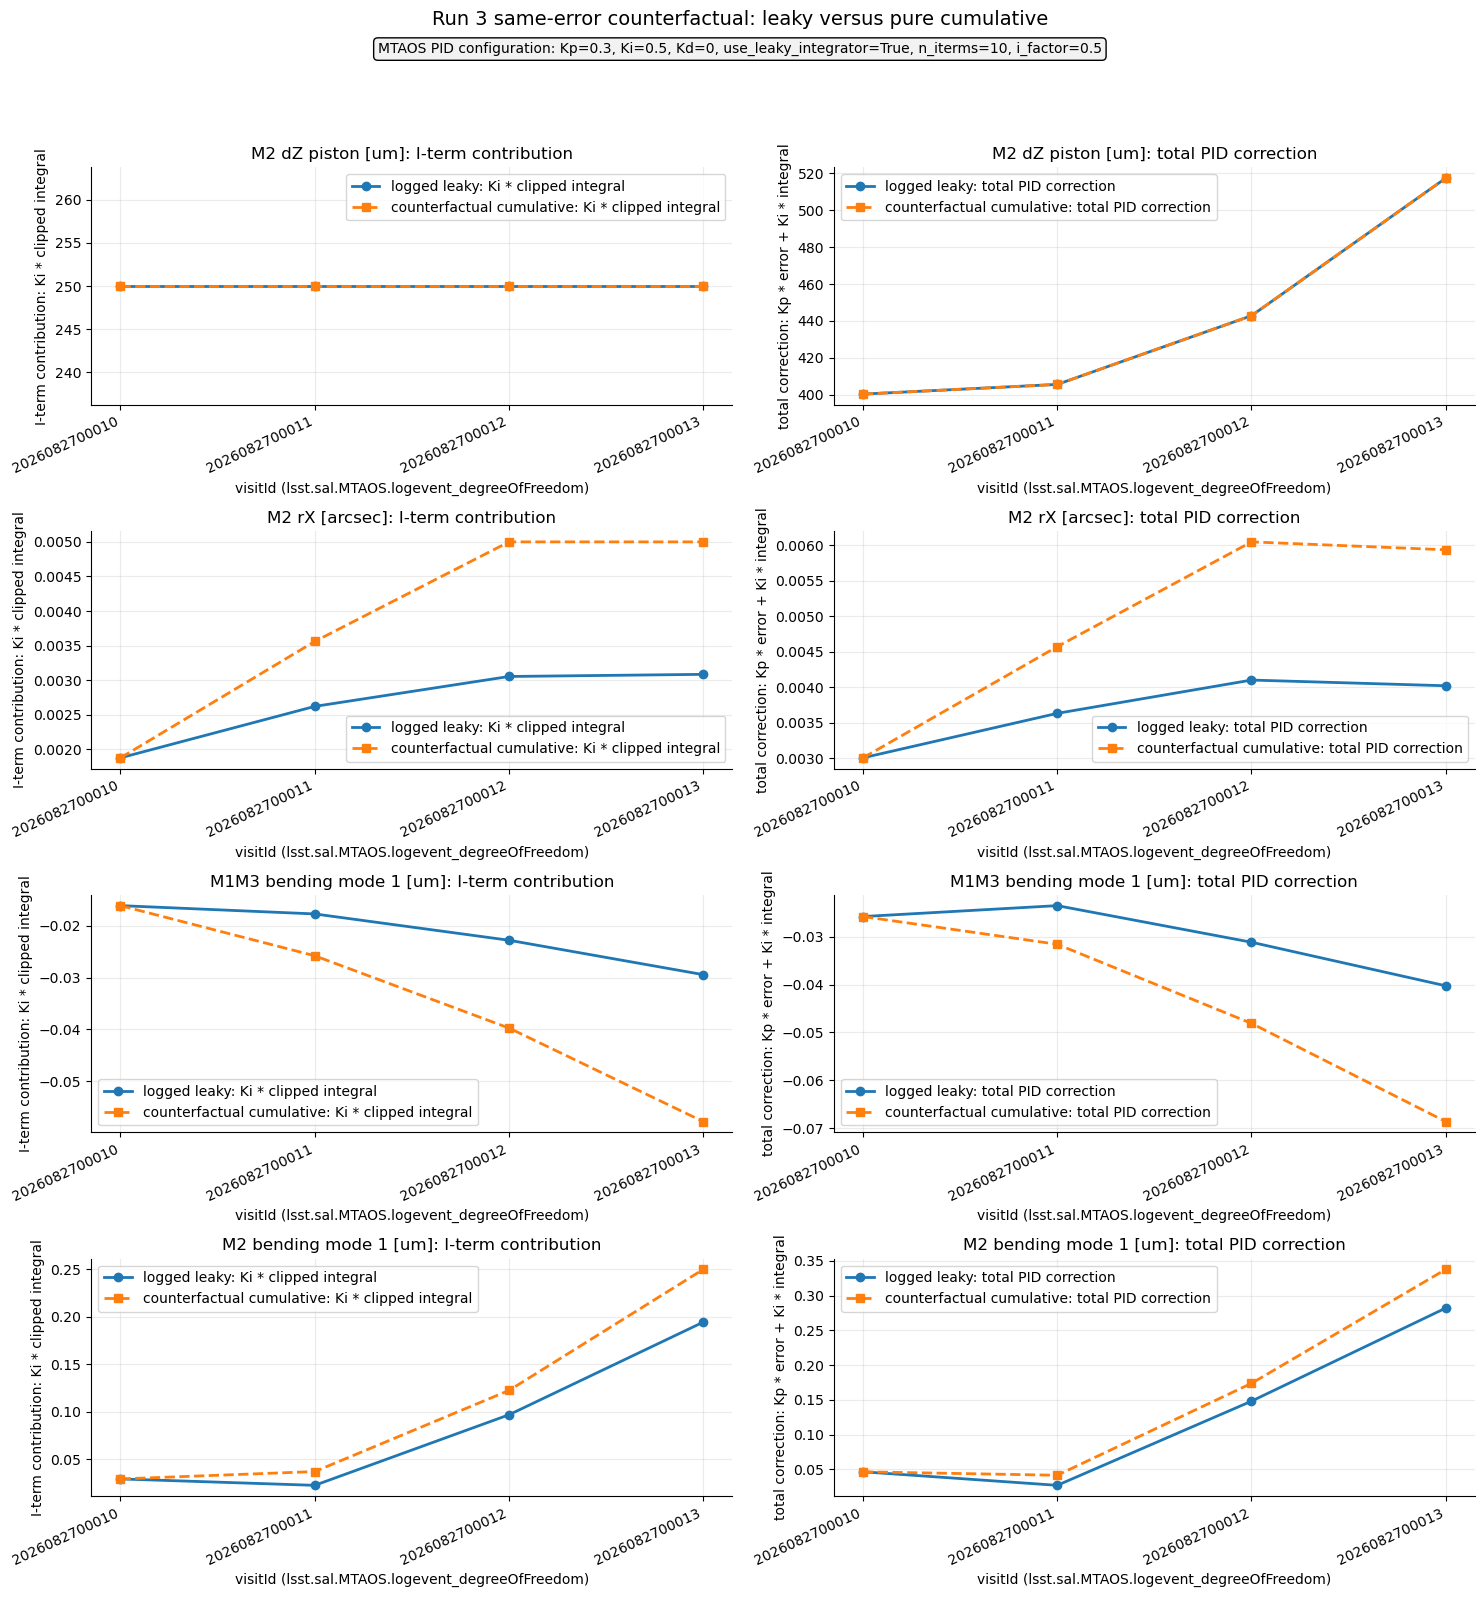

In [119]:
run_3_ki = gain_vector(RUNS["run_3_leaky_ki05"]["ki"])
visit_positions = np.arange(len(run_3))
visit_labels = run_3["visitId"].astype(str).tolist()
fig, axes = plt.subplots(
    len(DISPLAY_DOFS),
    2,
    figsize=(15, 4.0 * len(DISPLAY_DOFS)),
    squeeze=False,
)
counterfactual_rows = []

for row_index, global_dof in enumerate(DISPLAY_DOFS):
    index = pid_index(global_dof)
    leaky_clipped = vector_component(
        run_3["integral_clipped"],
        global_dof,
    )
    cumulative_clipped = vector_component(
        run_3["hypothetical_cumulative_clipped"],
        global_dof,
    )
    leaky_i_term = run_3_ki[index] * leaky_clipped
    cumulative_i_term = run_3_ki[index] * cumulative_clipped
    leaky_correction = vector_component(
        run_3["correction"],
        global_dof,
    )
    cumulative_correction = vector_component(
        run_3["hypothetical_cumulative_correction"],
        global_dof,
    )

    integral_axis = axes[row_index, 0]
    integral_axis.plot(
        visit_positions,
        leaky_i_term,
        "o-",
        linewidth=2,
        label="logged leaky: Ki * clipped integral",
    )
    integral_axis.plot(
        visit_positions,
        cumulative_i_term,
        "s--",
        linewidth=2,
        label="counterfactual cumulative: Ki * clipped integral",
    )
    integral_axis.set_title(
        f"{DOF_LABELS[global_dof]}: I-term contribution"
    )
    integral_axis.set_ylabel("I-term contribution: Ki * clipped integral")
    integral_axis.legend()

    correction_axis = axes[row_index, 1]
    correction_axis.plot(
        visit_positions,
        leaky_correction,
        "o-",
        linewidth=2,
        label="logged leaky: total PID correction",
    )
    correction_axis.plot(
        visit_positions,
        cumulative_correction,
        "s--",
        linewidth=2,
        label="counterfactual cumulative: total PID correction",
    )
    correction_axis.set_title(
        f"{DOF_LABELS[global_dof]}: total PID correction"
    )
    correction_axis.set_ylabel("total correction: Kp * error + Ki * integral")
    correction_axis.legend()

    for axis in [integral_axis, correction_axis]:
        axis.set_xticks(
            visit_positions,
            visit_labels,
            rotation=25,
            ha="right",
        )
        axis.set_xlabel(
            "visitId (lsst.sal.MTAOS.logevent_degreeOfFreedom)"
        )

    for visit_position, (_, pid_row) in enumerate(run_3.iterrows(), start=1):
        counterfactual_rows.append(
            {
                "visitId": int(pid_row["visitId"]),
                "history_step": visit_position,
                "DOF": global_dof,
                "error": pid_row["error"][index],
                "leakyIntegralRaw": pid_row["integral_raw"][index],
                "cumulativeIntegralRaw": pid_row[
                    "hypothetical_cumulative_raw"
                ][index],
                "leakyIntegralClipped": leaky_clipped[visit_position - 1],
                "cumulativeIntegralClipped": cumulative_clipped[
                    visit_position - 1
                ],
                "leakyITerm": leaky_i_term[visit_position - 1],
                "cumulativeITerm": cumulative_i_term[visit_position - 1],
                "loggedLeakyCorrection": leaky_correction[visit_position - 1],
                "cumulativeCorrection": cumulative_correction[
                    visit_position - 1
                ],
                "leakyMinusCumulativeCorrection": (
                    leaky_correction[visit_position - 1]
                    - cumulative_correction[visit_position - 1]
                ),
            }
        )

fig.suptitle(
    "Run 3 same-error counterfactual: leaky versus pure cumulative",
    fontsize=14,
    y=0.995,
)
fig.text(
    0.5,
    0.975,
    pid_configuration_label(RUNS["run_3_leaky_ki05"]),
    ha="center",
    va="top",
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "0.95"},
)
fig.tight_layout(rect=(0, 0, 1, 0.94))

counterfactual_table = pd.DataFrame(counterfactual_rows)
display(counterfactual_table)

## Verification summary

The three rows below correspond directly to the three evidence sections.
Recurrence and correction residuals compare the parsed PID messages with the
configured controller equations; values below `1e-4` pass.

In [120]:
tolerance = 1e-4
run_1_accumulates = (
    bool(run_1.iloc[0]["integral_equals_error"])
    and bool((~run_1.iloc[1:]["integral_equals_error"]).any())
    and float(run_1["integral_residual_max"].max()) < tolerance
)

run_2_reset_sample = run_2.loc[
    run_2["visitId"] == 2026082700008
].iloc[0]
run_2_next_sample = run_2.loc[
    run_2["visitId"] == 2026082700009
].iloc[0]
run_2_resets = (
    bool(run_2_reset_sample["integral_equals_error"])
    and not bool(run_2_next_sample["integral_equals_error"])
    and len(efd_data["run_2_cumulative_ki05"]["stop_closed_loop_command"]) > 0
    and len(efd_data["run_2_cumulative_ki05"]["start_closed_loop_command"]) > 0
)

run_3_integral_residual = float(run_3["integral_residual_max"].max())
run_3_correction_residual = float(run_3["correction_residual_max"].max())
run_3_differs_from_cumulative = any(
    not np.allclose(leaky, cumulative, atol=1e-6, rtol=1e-8)
    for leaky, cumulative in zip(
        run_3.iloc[1:]["integral_clipped"],
        run_3.iloc[1:]["hypothetical_cumulative_clipped"],
    )
)
run_3_is_leaky = (
    run_3_integral_residual < tolerance
    and run_3_correction_residual < tolerance
    and run_3_differs_from_cumulative
)

verification_summary = pd.DataFrame(
    [
        {
            "evidence": "Run 1: ordinary accumulation",
            "PID samples": len(run_1),
            "max recurrence residual": float(
                run_1["integral_residual_max"].max()
            ),
            "max correction residual": float(
                run_1["correction_residual_max"].max()
            ),
            "PASS": run_1_accumulates,
        },
        {
            "evidence": "Run 2: reset at stop/start",
            "PID samples": len(run_2),
            "max recurrence residual": float(
                run_2["integral_residual_max"].max()
            ),
            "max correction residual": float(
                run_2["correction_residual_max"].max()
            ),
            "PASS": run_2_resets,
        },
        {
            "evidence": "Run 3: leaky recurrence and correction",
            "PID samples": len(run_3),
            "max recurrence residual": run_3_integral_residual,
            "max correction residual": run_3_correction_residual,
            "PASS": run_3_is_leaky,
        },
    ]
).set_index("evidence")
display(verification_summary)

if verification_summary["PASS"].all():
    print("PASS: all three controller-history claims are verified.")
else:
    print("Review failed checks before drawing conclusions.")

,PID samples,max recurrence residual,max correction residual,PASS
evidence,,,,
Run 1: ordinary accumulation,3,0.000004,1.000000e-06,True
Run 2: reset at stop/start,5,0.000005,3.000000e-06,True
Run 3: leaky recurrence and correction,4,0.000007,3.000000e-06,True


PASS: all three controller-history claims are verified.


## Interpretation

A successful execution supports the following progression:

1. **RSO-439 fixes the original bug.** Run 1 accumulates integral history
   beyond the current error while one closed loop remains active. `Ki=0`
   ensures that this observation is about history retention alone.
2. **The lifecycle reset works.** Run 2 has accumulated history before the
   stop/start boundary, returns to `integral == error` for every active DOF at
   visit `0008`, and begins accumulating again at visit `0009`.
3. **The leaky algorithm is active.** Run 3 matches the finite weighted sum
   with `i_factor=0.5`, rather than the cumulative alternative, and its
   corrections match the configured PID equation. The same-error
   counterfactual isolates how that history changes `Ki * I` and the commanded
   correction relative to pure accumulation.
Integral clipping must be considered when comparing outputs. For M2 piston,
both algorithms reach the same limit immediately, so their corrections can
look nearly identical even though their raw integral histories differ. An
unsaturated term such as M2 `rX` exposes the leaky behavior more clearly.

Four run-3 samples verify exponential weighting but do not exercise the
`n_iterms=10` history cutoff. That would require at least eleven samples in a
single uninterrupted lifecycle. Because the BTS playlist is fixed and does
not react to applied corrections, these tests validate controller arithmetic
and command differences; they do not measure optical convergence or the
closed-loop response of the real telescope.

## Additional analysis: BTS replay `wavefrontError` identity

This analysis is independent of the PID-configuration comparison above. It
tests whether resetting and replaying the BTS image playlist reproduces the
same WEP outputs. The reference playlist pass contains `visitId` values
`2026082700001-0003`; the replayed pass contains `2026082700010-0012`.
Pairs `0001<->0010`, `0002<->0011`, and `0003<->0012` represent the same
three predetermined image inputs. MTAOS corrections do not alter subsequent
BTS images.

The comparison uses `lsst.sal.MTAOS.logevent_wavefrontError` directly. Each
`nollZernikeValuesN` coefficient is paired with its corresponding
`nollZernikeIndicesN` field; the Noll sequence is sparse and must not be
inferred from the array slot. This analysis is intentionally restricted to
`Z4-Z19` and `Z22-Z26`. Values are in microns. The four `sensorId`
measurements are matched individually. Because both the image data and WEP
processing are expected to be the same, every reference/replayed
`nollZernikeValues` coefficient should be exactly equal. Any mismatch fails
this input-identity
check and requires investigation.

wavefrontError array-slot to Noll-index mapping


,arraySlot,nollZernikeIndices,Zernike
0,0,4,Z4
1,1,5,Z5
2,2,6,Z6
3,3,7,Z7
4,4,8,Z8
5,5,9,Z9
6,6,10,Z10
7,7,11,Z11
8,8,12,Z12
9,9,13,Z13


,,sensorCount,nollCount,coefficientCount,exactCoefficientCount,allCoefficientsExact,rmsDifferenceMicron,maxAbsDifferenceMicron
reference visitId,replayed visitId,,,,,,,
2026082700001,2026082700010,4,21,84,0,False,0.001475,0.006890
2026082700002,2026082700011,4,21,84,0,False,0.033103,0.196107
2026082700003,2026082700012,4,21,84,0,False,0.018942,0.081459


FAIL: 252 of 252 paired nollZernikeValues coefficients differ. Investigate the playlist or WEP processing before treating the paired inputs as identical.


,visitId_reference,pairedVisitId,sensorId,nollZernikeIndices,nollZernikeValues_reference,nollZernikeValues_replayed,differenceMicron,absDifferenceMicron
149,2026082700002,2026082700011,203,6,0.397796,0.201690,-0.196107,0.196107
148,2026082700002,2026082700011,203,5,-0.934055,-0.789109,0.144945,0.144945
150,2026082700002,2026082700011,203,7,-0.497455,-0.597148,-0.099693,0.099693
232,2026082700003,2026082700012,203,5,-1.016904,-0.935445,0.081459,0.081459
151,2026082700002,2026082700011,203,8,0.061689,-0.014386,-0.076074,0.076074
155,2026082700002,2026082700011,203,12,-0.183370,-0.107679,0.075691,0.075691
170,2026082700003,2026082700012,191,6,0.193716,0.124613,-0.069103,0.069103
153,2026082700002,2026082700011,203,10,0.027282,0.091353,0.064071,0.064071
190,2026082700003,2026082700012,195,5,0.307962,0.363029,0.055067,0.055067
191,2026082700003,2026082700012,195,6,0.727225,0.778012,0.050788,0.050788


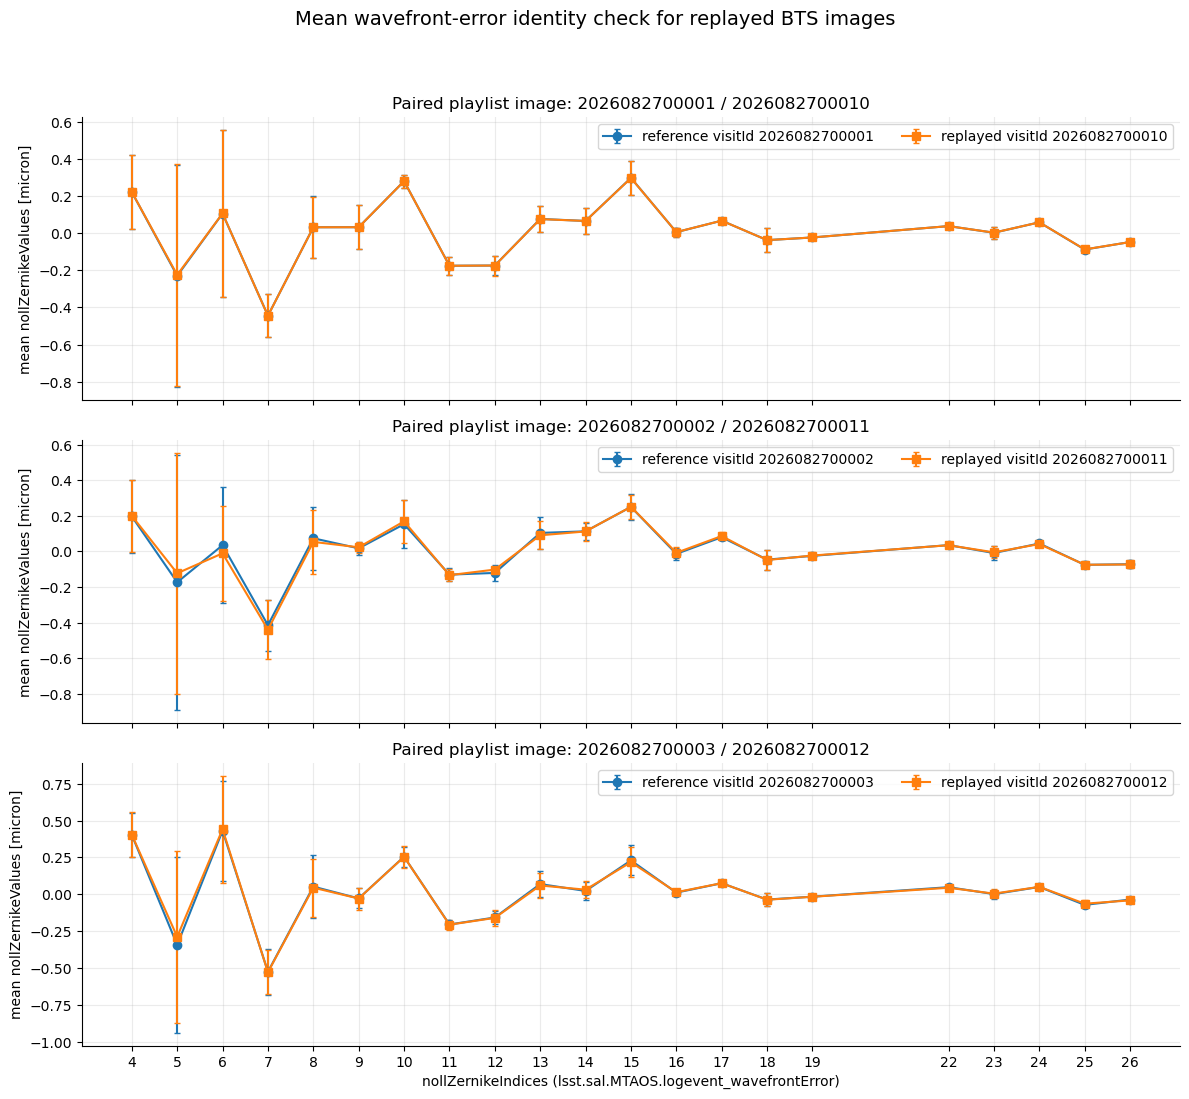

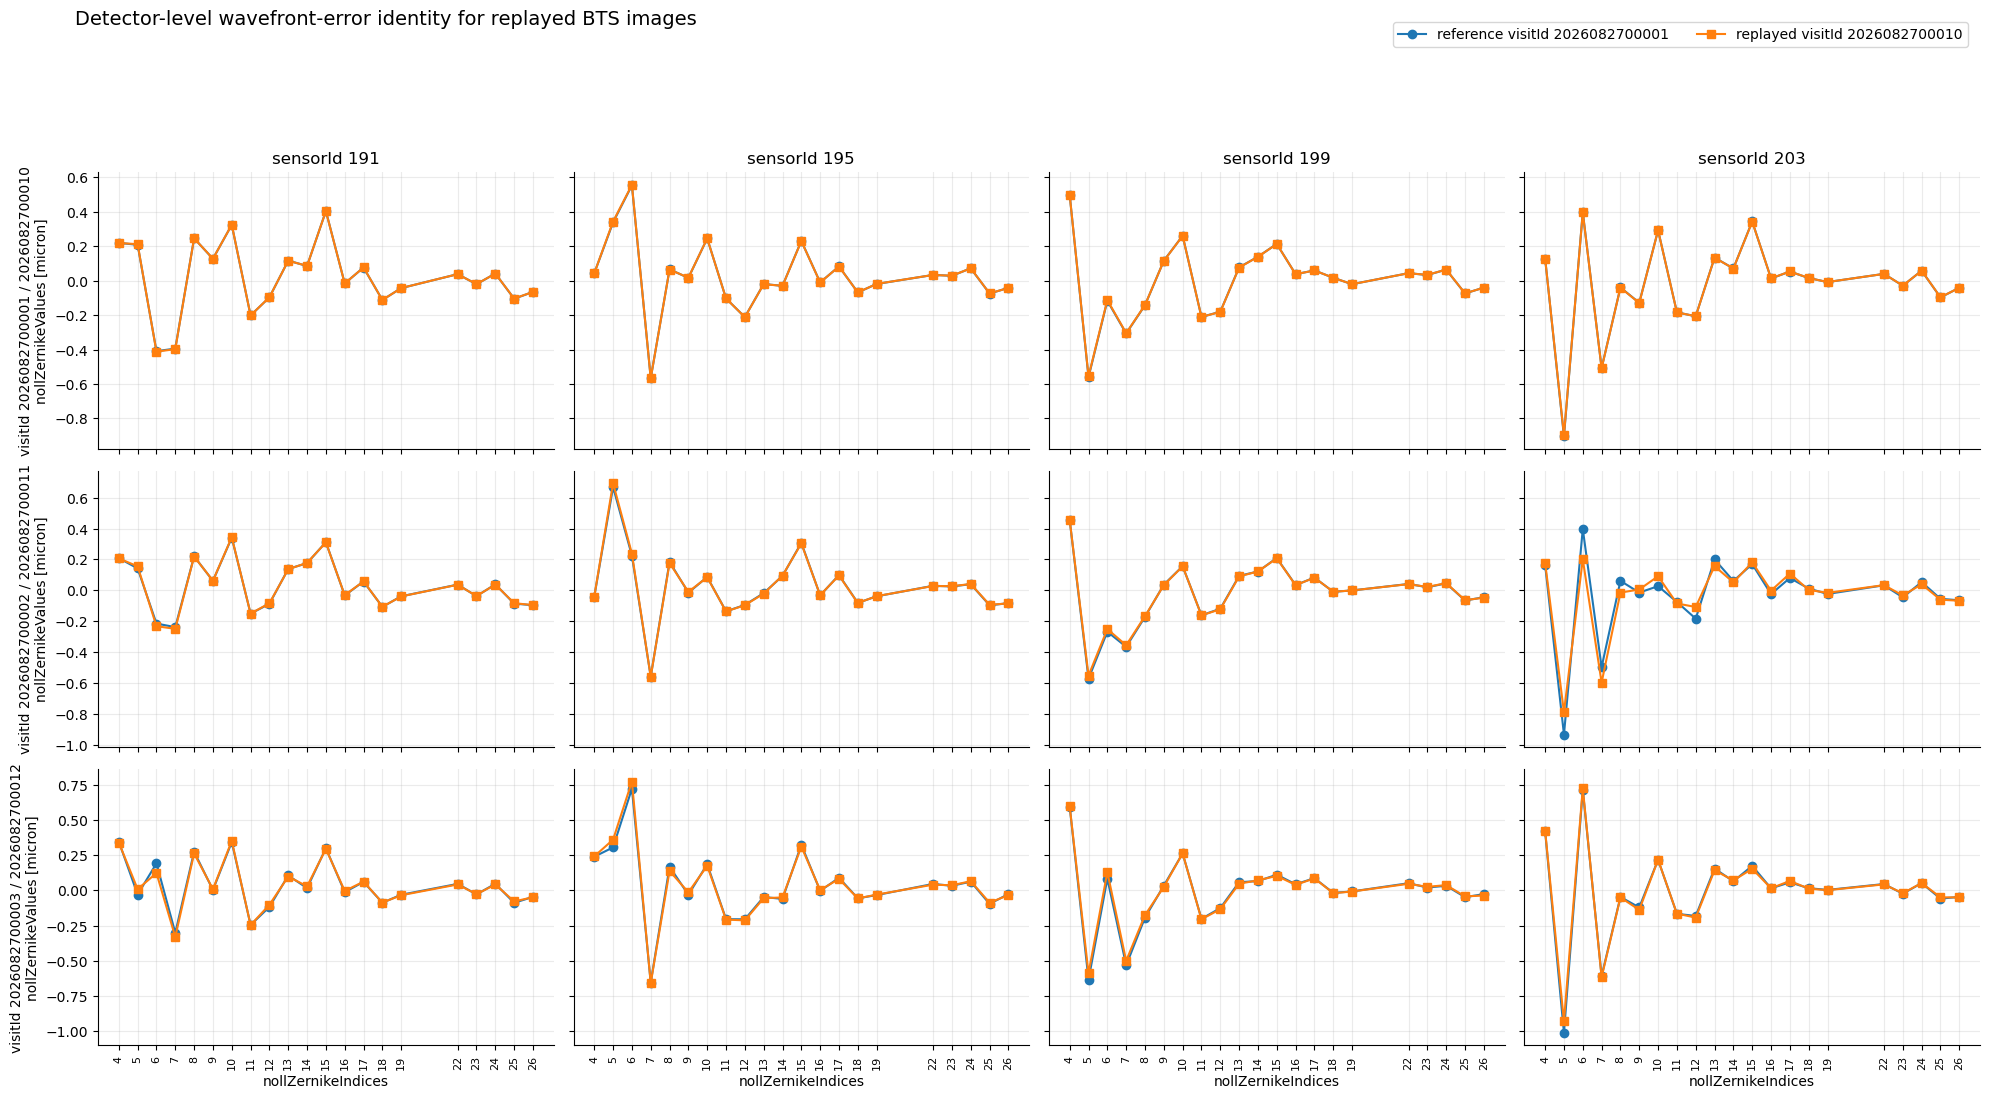

In [121]:
def array_field_slots(frame, prefix):
    slots = []
    for column in frame.columns:
        name = str(column)
        if name.startswith(prefix) and name.removeprefix(prefix).isdigit():
            slots.append(int(name.removeprefix(prefix)))
    return set(slots)


def wavefront_error_long(frame):
    required = {"visitId", "sensorId"}
    if frame.empty or not required.issubset(frame.columns):
        return pd.DataFrame()

    slots = sorted(
        array_field_slots(frame, "nollZernikeIndices")
        & array_field_slots(frame, "nollZernikeValues")
    )
    rows = []
    for timestamp, event in frame.sort_index().iterrows():
        for slot in slots:
            noll_index = pd.to_numeric(
                event[f"nollZernikeIndices{slot}"],
                errors="coerce",
            )
            value = pd.to_numeric(
                event[f"nollZernikeValues{slot}"],
                errors="coerce",
            )
            if not np.isfinite(noll_index) or not np.isfinite(value):
                continue
            noll_index = int(noll_index)
            if noll_index not in WFE_NOLL_INDICES:
                continue
            rows.append(
                {
                    "time": timestamp,
                    "visitId": int(event["visitId"]),
                    "sensorId": int(event["sensorId"]),
                    "arraySlot": slot,
                    "nollZernikeIndices": noll_index,
                    "Zernike": f"Z{noll_index}",
                    "nollZernikeValues": float(value),
                }
            )

    result = pd.DataFrame(rows)
    keys = ["visitId", "sensorId", "nollZernikeIndices"]
    if not result.empty and result.duplicated(keys).any():
        raise ValueError("Duplicate wavefrontError coefficients were found")
    return result


reference_wfe = wavefront_error_long(
    efd_data["run_1_ki0"]["wavefront_error"]
)
replayed_wfe = wavefront_error_long(
    efd_data["run_3_leaky_ki05"]["wavefront_error"]
)
expected_noll_indices = set(WFE_NOLL_INDICES)
for pass_name, pass_wfe in [
    ("reference playlist pass", reference_wfe),
    ("replayed playlist pass", replayed_wfe),
]:
    observed_noll_indices = set(
        pass_wfe["nollZernikeIndices"].unique()
    )
    if observed_noll_indices != expected_noll_indices:
        raise ValueError(
            f"{pass_name}: expected Noll indices "
            f"{sorted(expected_noll_indices)}, "
            f"found {sorted(observed_noll_indices)}."
        )

wfe_pair_map = dict(WFE_VISIT_PAIRS)
reference_wfe = reference_wfe.loc[
    reference_wfe["visitId"].isin(wfe_pair_map)
].copy()
reference_wfe["pairedVisitId"] = reference_wfe["visitId"].map(
    wfe_pair_map
)
replayed_wfe = replayed_wfe.loc[
    replayed_wfe["visitId"].isin(wfe_pair_map.values())
].copy()

wfe_match_keys = ["sensorId", "nollZernikeIndices"]
paired_wfe = reference_wfe.merge(
    replayed_wfe,
    left_on=["pairedVisitId", *wfe_match_keys],
    right_on=["visitId", *wfe_match_keys],
    suffixes=("_reference", "_replayed"),
    validate="one_to_one",
)
if (
    len(paired_wfe) != len(reference_wfe)
    or len(paired_wfe) != len(replayed_wfe)
):
    raise ValueError(
        "Not every reference wavefrontError coefficient matched a replayed "
        "coefficient by paired visitId, sensorId, and nollZernikeIndices."
    )

paired_wfe["differenceMicron"] = (
    paired_wfe["nollZernikeValues_replayed"]
    - paired_wfe["nollZernikeValues_reference"]
)
paired_wfe["exactMatch"] = (
    paired_wfe["nollZernikeValues_replayed"]
    == paired_wfe["nollZernikeValues_reference"]
)

noll_mapping = reference_wfe[
    ["arraySlot", "nollZernikeIndices", "Zernike"]
]
noll_mapping = noll_mapping.drop_duplicates().sort_values("arraySlot")
print("wavefrontError array-slot to Noll-index mapping")
display(noll_mapping.reset_index(drop=True))

wfe_pair_summary = (
    paired_wfe.groupby(["visitId_reference", "pairedVisitId"], sort=False)
    .agg(
        sensorCount=("sensorId", "nunique"),
        nollCount=("nollZernikeIndices", "nunique"),
        coefficientCount=("exactMatch", "size"),
        exactCoefficientCount=("exactMatch", "sum"),
        allCoefficientsExact=("exactMatch", "all"),
        rmsDifferenceMicron=(
            "differenceMicron",
            lambda values: np.sqrt(np.mean(np.square(values))),
        ),
        maxAbsDifferenceMicron=(
            "differenceMicron",
            lambda values: np.max(np.abs(values)),
        ),
    )
    .rename_axis(["reference visitId", "replayed visitId"])
)
display(wfe_pair_summary)

if paired_wfe["exactMatch"].all():
    print(
        "PASS: reference and replayed nollZernikeValues are exactly equal."
    )
else:
    mismatch_count = int((~paired_wfe["exactMatch"]).sum())
    print(
        f"FAIL: {mismatch_count} of {len(paired_wfe)} paired "
        "nollZernikeValues coefficients differ. Investigate the playlist "
        "or WEP processing before treating the paired inputs as identical."
    )
    wfe_mismatches = paired_wfe.loc[
        ~paired_wfe["exactMatch"],
        [
            "visitId_reference",
            "pairedVisitId",
            "sensorId",
            "nollZernikeIndices",
            "nollZernikeValues_reference",
            "nollZernikeValues_replayed",
            "differenceMicron",
        ],
    ].copy()
    wfe_mismatches["absDifferenceMicron"] = wfe_mismatches[
        "differenceMicron"
    ].abs()
    display(
        wfe_mismatches.sort_values(
            "absDifferenceMicron",
            ascending=False,
        ).head(20)
    )

fig, axes = plt.subplots(len(WFE_VISIT_PAIRS), 1, figsize=(12, 11), sharex=True)
noll_indices = sorted(paired_wfe["nollZernikeIndices"].unique())
for axis, (reference_visit, replayed_visit) in zip(axes, WFE_VISIT_PAIRS):
    visit_pair = paired_wfe.loc[
        (paired_wfe["visitId_reference"] == reference_visit)
        & (paired_wfe["pairedVisitId"] == replayed_visit)
    ]
    for suffix, label, marker in [
        ("reference", f"reference visitId {reference_visit}", "o"),
        ("replayed", f"replayed visitId {replayed_visit}", "s"),
    ]:
        statistics = visit_pair.groupby("nollZernikeIndices")[
            f"nollZernikeValues_{suffix}"
        ].agg(["mean", "std"])
        axis.errorbar(
            statistics.index,
            statistics["mean"],
            yerr=statistics["std"],
            marker=marker,
            capsize=2,
            label=label,
        )
    axis.set_ylabel("mean nollZernikeValues [micron]")
    axis.set_title(
        f"Paired playlist image: {reference_visit} / {replayed_visit}"
    )
    axis.legend(ncol=2)

axes[-1].set_xticks(noll_indices)
axes[-1].set_xlabel(
    "nollZernikeIndices (lsst.sal.MTAOS.logevent_wavefrontError)"
)
fig.suptitle(
    "Mean wavefront-error identity check for replayed BTS images",
    fontsize=14,
    y=0.995,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))

sensor_ids = sorted(paired_wfe["sensorId"].unique())
fig, axes = plt.subplots(
    len(WFE_VISIT_PAIRS),
    len(sensor_ids),
    figsize=(20, 11),
    sharex=True,
    sharey="row",
)
for row, (reference_visit, replayed_visit) in enumerate(WFE_VISIT_PAIRS):
    for column, sensor_id in enumerate(sensor_ids):
        axis = axes[row, column]
        detector_pair = paired_wfe.loc[
            (paired_wfe["visitId_reference"] == reference_visit)
            & (paired_wfe["pairedVisitId"] == replayed_visit)
            & (paired_wfe["sensorId"] == sensor_id)
        ].sort_values("nollZernikeIndices")
        axis.plot(
            detector_pair["nollZernikeIndices"],
            detector_pair["nollZernikeValues_reference"],
            "o-",
            label=f"reference visitId {reference_visit}",
        )
        axis.plot(
            detector_pair["nollZernikeIndices"],
            detector_pair["nollZernikeValues_replayed"],
            "s-",
            label=f"replayed visitId {replayed_visit}",
        )
        if row == 0:
            axis.set_title(f"sensorId {sensor_id}")
        if column == 0:
            axis.set_ylabel(
                f"visitId {reference_visit} / {replayed_visit}\n"
                "nollZernikeValues [micron]"
            )
        if row == len(WFE_VISIT_PAIRS) - 1:
            axis.set_xticks(noll_indices)
            axis.tick_params(axis="x", labelrotation=90, labelsize=8)
            axis.set_xlabel("nollZernikeIndices")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper right",
    bbox_to_anchor=(0.99, 0.99),
    ncol=2,
)
fig.suptitle(
    "Detector-level wavefront-error identity for replayed BTS images",
    fontsize=14,
    x=0.04,
    y=0.995,
    ha="left",
)
fig.tight_layout(rect=(0, 0, 1, 0.91))